In [1]:
import os
import json
from PIL import Image

import torch
import torch.utils.data as data
import torchvision.transforms.v2 as tfs
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm

from sklearn.datasets import load_iris

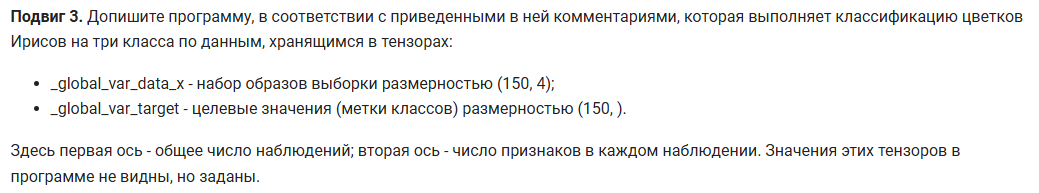

In [78]:
import torch
import torch.utils.data as data
import torch.nn as nn
import torch.optim as optim

iris = load_iris()
_global_var_data_x = torch.tensor(iris.data, dtype=torch.float32)
_global_var_target = torch.tensor(iris.target, dtype=torch.long)


class IrisDataset(data.Dataset):
    def __init__(self):
        self.data = _global_var_data_x # тензор размерностью (150, 4), тип float32
        self.target = _global_var_target # тензор размерностью (150, ), тип int64 (long)

        self.length = self.data.shape[0] # размер выборки
        self.categories = ['setosa' 'versicolor' 'virginica'] # названия классов
        self.features = ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

    def __getitem__(self, item):
        # возврат образа по индексу item в виде кортежа: (данные, целевое значение)
        return (self.data[item], self.target[item])

    def __len__(self):
        # возврат размера выборки
        return self.length


class IrisClassModel(nn.Module):
    def __init__(self, in_features=4, out_features=3):
        super().__init__()
        # модель нейронной сети из двух полносвязных слоев:
        # 1-й слой: число входов in_features, число нейронов 16
        self.layer1 = nn.Linear(in_features, 16)
        # 2-й слой: число нейронов out_features
        self.layer2 = nn.Linear(16, out_features)

    def forward(self, x):
        # тензор x пропускается через 1-й слой
        x = self.layer1(x)
        # через функцию активации torch.relu()
        x = torch.relu(x)
        # через второй слой
        y = self.layer2(x)
        # полученный (вычисленный) тензор возвращается
        return y


torch.manual_seed(11)

# создать модель IrisClassModel с числом входов 4 и числом выходов 3
model = IrisClassModel(4, 3)
# перевести модель в режим обучения
model.train()

epochs = 10 # число эпох обучения
batch_size = 8 # размер батча

# создать объект класса IrisDataset
d_train = IrisDataset() 
# создать объект класса DataLoader с размером пакетов batch_size и перемешиванием образов выборки
train_data = data.DataLoader(d_train, batch_size=batch_size, shuffle=True)

optimizer = optim.Adam(model.parameters(), lr=0.01) # создать оптимизатор Adam для обучения модели с шагом обучения 0.01
loss_func = nn.CrossEntropyLoss() # создать функцию потерь с помощью класса CrossEntropyLoss (используется при многоклассовой классификации)

for _e in range(epochs): # итерации по эпохам
    for x_train, y_train in train_data:
        predict = model(x_train) # вычислить прогноз модели для данных x_train
        loss = loss_func(predict, y_train) # вычислить значение функции потерь

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

# перевести модель в режим эксплуатации
model.eval()
# выполнить прогноз модели по всем данным выборки
logits = model(d_train.data)
pred = torch.argmax(logits, dim=1)
# вычислить долю верных классификаций (сохранить, как вещественное число, а не тензор)

Q = (torch.sum(pred==d_train.target) / len(d_train)).item() 
Q = torch.mean((pred==d_train.target).float()).item() 
Q

0.9599999785423279

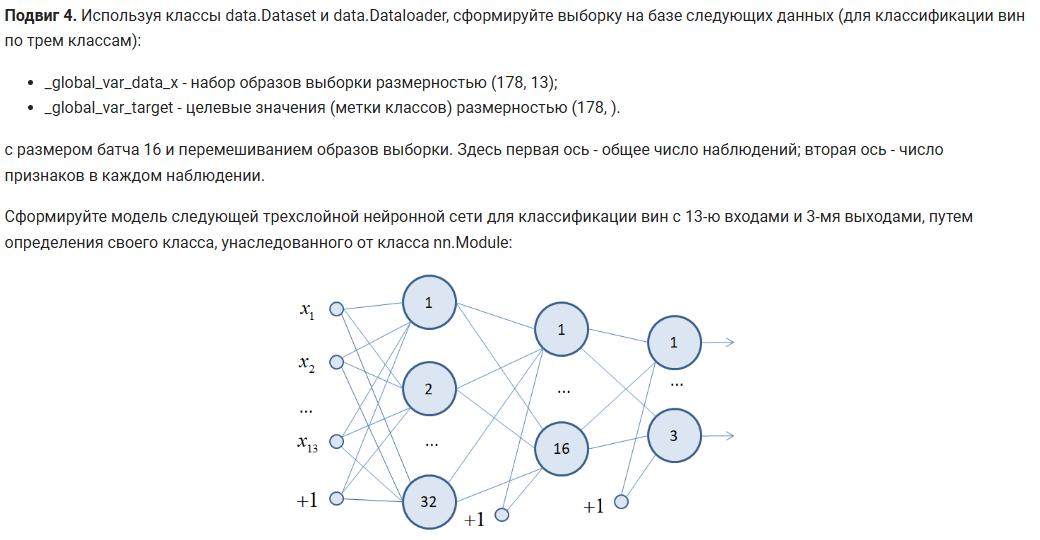

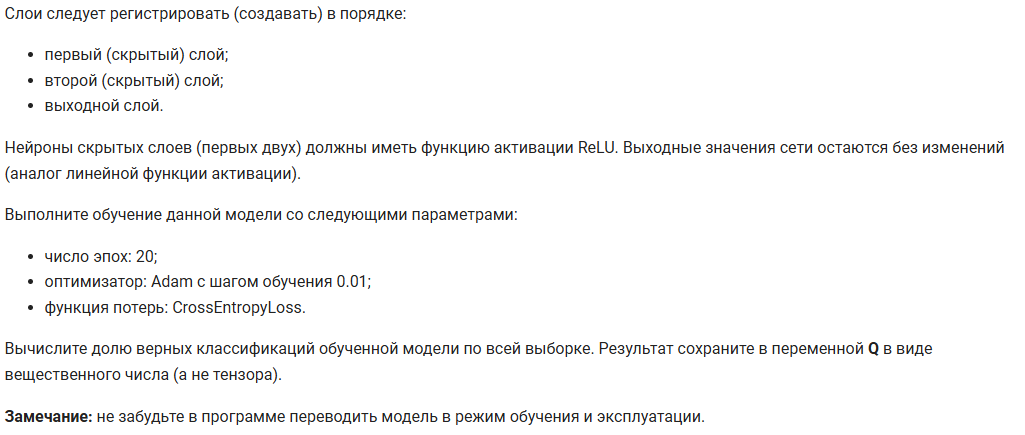

In [93]:
import torch
import torch.utils.data as data
import torch.nn as nn
import torch.optim as optim

from sklearn.datasets import load_wine
import torch


wine_data = load_wine()

# Признаки и целевые значения
_global_var_data_x = torch.tensor(wine_data.data, dtype=torch.float32)
_global_var_target = torch.tensor(wine_data.target, dtype=torch.long)


class WineDataset(data.Dataset):
    def __init__(self):
        self.data = _global_var_data_x # тензор размерностью (178, 13), тип float32
        self.target = _global_var_target # тензор размерностью (178, ), тип int64 (long)

        self.length = len(self.data) # размер выборки
        self.categories = ['class_0', 'class_1', 'class_2'] # названия классов

    def __getitem__(self, item):
        # возврат образа по индексу item в виде кортежа: (данные, целевое значение)
        return (self.data[item], self.target[item])

    def __len__(self):
        # возврат размера выборки
        return self.length


class IrisClassModel(nn.Module):
    def __init__(self, in_features=13, hidden_features1=32, hidden_features2=16, out_features=3):
        super().__init__()
        self.layer1 = nn.Linear(in_features, hidden_features1)
        self.layer2 = nn.Linear(hidden_features1, hidden_features2)
        self.layer3 = nn.Linear(hidden_features2, out_features)


    def forward(self, x):
        # тензор x пропускается через 1-й слой
        x = torch.relu(self.layer1(x))
        x = torch.relu(self.layer2(x))
        y = self.layer3(x)
        return y
        

# здесь продолжайте программу
d_train = WineDataset()
batch_size = 16
train_data = data.DataLoader(d_train, batch_size=batch_size, shuffle=True)

model = IrisClassModel()
model.train()
optimizer = optim.Adam(model.parameters(), lr=0.01)
loss_func = nn.CrossEntropyLoss()

epochs = 20

for e in range(epochs):
    for x, y in train_data:
        predict = model(x)
        loss = loss_func(predict, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()


model.eval()
logits = model(d_train.data)
pred = torch.argmax(logits, dim=1)
Q = torch.mean((pred==d_train.target).float()).item() 
Q



0.8539325594902039

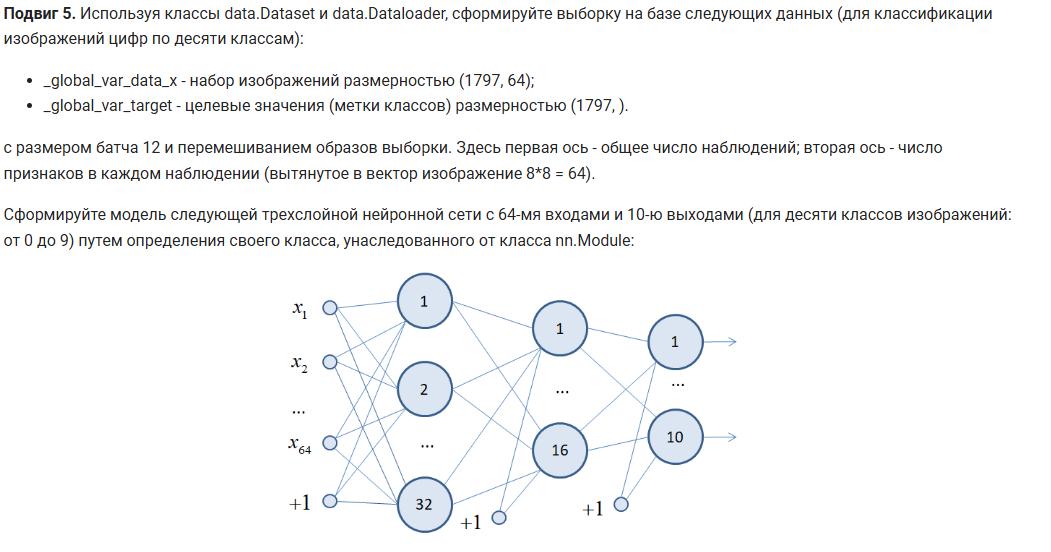

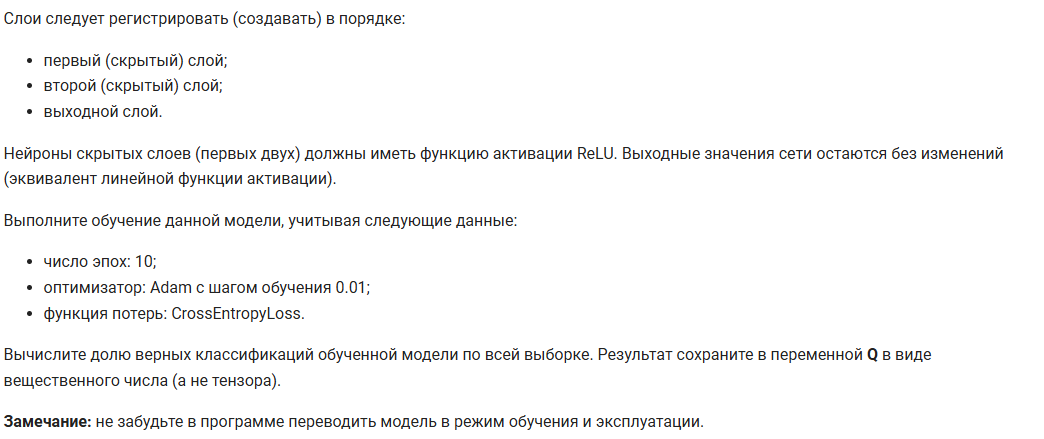


In [98]:
import torch
import torch.utils.data as data
import torch.nn as nn
import torch.optim as optim

from sklearn.datasets import load_digits

digits = load_digits()


# Признаки и целевые значения
_global_var_data_x = torch.tensor(digits.data, dtype=torch.float32)
_global_var_target = torch.tensor(digits.target, dtype=torch.int64)


class WineDataset(data.Dataset):
    def __init__(self):
        self.data = _global_var_data_x # тензор размерностью (1797, 64), тип float32
        self.target = _global_var_target # тензор размерностью (1797, ), тип int64 (long)

        self.length = len(self.data) # размер выборки

    def __getitem__(self, item):
        # возврат образа по индексу item в виде кортежа: (данные, целевое значение)
        return (self.data[item], self.target[item])

    def __len__(self):
        # возврат размера выборки
        return self.length


class DigitModel(nn.Module):
    def __init__(self, in_features=64, hidden_features1=32, hidden_features2=16, out_features=10):
        super().__init__()
        self.layer1 = nn.Linear(in_features, hidden_features1)
        self.layer2 = nn.Linear(hidden_features1, hidden_features2)
        self.layer3 = nn.Linear(hidden_features2, out_features)


    def forward(self, x):
        # тензор x пропускается через 1-й слой
        x = torch.relu(self.layer1(x))
        x = torch.relu(self.layer2(x))
        y = self.layer3(x)
        return y
        

# здесь продолжайте программу
d_train = WineDataset()
batch_size = 12
train_data = data.DataLoader(d_train, batch_size=batch_size, shuffle=True)

model = DigitModel()
model.train()
optimizer = optim.Adam(model.parameters(), lr=0.01)
loss_func = nn.CrossEntropyLoss()

epochs = 10

for e in range(epochs):
    for x, y in train_data:
        predict = model(x)
        loss = loss_func(predict, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()


model.eval()
logits = model(d_train.data)
pred = torch.argmax(logits, dim=1)
Q = torch.mean((pred==d_train.target).float()).item() 
Q



0.9794101119041443

In [102]:
import torch

t = torch.empty(128).fill_(13)

# t.resize_(16, 4)
t


tensor([13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13.,
        13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13.,
        13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13.,
        13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13.,
        13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13.,
        13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13.,
        13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13.,
        13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13.,
        13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13., 13.,
        13., 13.])